### Part 1 - Set up the Evaluation Mental Model
#### Step 1 - Import TensorFlow and Supporting Tools

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

tf.keras.utils.set_random_seed(42)

In [2]:
try:
    import tensorflow_datasets as tfds
except ImportError:
    import sys
    import subprocess
    subprocess.call([sys.executable, '-m', 'pip', 'install', 'tensorflow_datasets'])
    import tensorflow_datasets as tfds

#### Step 2 - Review the Three Data Splits


In [3]:
# Loading from Internet
# train_data, val_data, test_data = tfds.load(
#     name='movie_review', split=['train[:12000]', 'test[12000:16000]', 'test[:5000]'], as_supervised=True,
# )

In [4]:
from datasets import load_from_disk

# Load from local disk (no internet needed)
dataset = load_from_disk("./imdb_stanfordnlp")
dataset = dataset.shuffle(seed=42)

train_data = dataset["train"].select(range(12000))
val_data = dataset["train"].select(range(12000,16000))
test_data  = dataset["test"].select(range(5000))

train_data = tf.data.Dataset.from_tensor_slices((
        list(train_data["text"]),
        list(train_data["label"])
    ))
val_data = tf.data.Dataset.from_tensor_slices((
        list(val_data["text"]),
        list(val_data["label"])
    ))
test_data  = tf.data.Dataset.from_tensor_slices((
        list(test_data["text"]),
        list(test_data["label"])
    ))

print(train_data)
print(val_data)
print(test_data)

<_TensorSliceDataset element_spec=(TensorSpec(shape=(), dtype=tf.string, name=None), TensorSpec(shape=(), dtype=tf.int32, name=None))>
<_TensorSliceDataset element_spec=(TensorSpec(shape=(), dtype=tf.string, name=None), TensorSpec(shape=(), dtype=tf.int32, name=None))>
<_TensorSliceDataset element_spec=(TensorSpec(shape=(), dtype=tf.string, name=None), TensorSpec(shape=(), dtype=tf.int32, name=None))>


In [5]:
for review, label in train_data.take(2):
    print("Review: ", review.numpy().decode("utf-8")[:700], "...")
    print("Label: ", label.numpy())
    print("-" * 100)

Review:  There is no relation at all between Fortier and Profiler but the fact that both are police series about violent crimes. Profiler looks crispy, Fortier looks classic. Profiler plots are quite simple. Fortier's plot are far more complicated... Fortier looks more like Prime Suspect, if we have to spot similarities... The main character is weak and weirdo, but have "clairvoyance". People like to compare, to judge, to evaluate. How about just enjoying? Funny thing too, people writing Fortier looks American but, on the other hand, arguing they prefer American series (!!!). Maybe it's the language, or the spirit, but I think this series is more English than American. By the way, the actors are real ...
Label:  1
----------------------------------------------------------------------------------------------------
Review:  This movie is a great. The plot is very true to the book which is a classic written by Mark Twain. The movie starts of with a scene where Hank sings a song with a bun

In [6]:
max_token = 10000
sequence_length = 180

vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=max_token,
    output_mode="int",
    output_sequence_length=sequence_length
)
train_text_only = train_data.map(lambda text, label: text)
vectorizer.adapt(train_text_only.batch(1024))
vocab = vectorizer.get_vocabulary()
print("Vocabulary size: ", len(vocab))
print("First 20 words: ", vocab[:20])

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 106ms/step
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 106ms/step
Vocabulary size:  10000
First 20 words:  ['', '[UNK]', np.str_('the'), np.str_('and'), np.str_('a'), np.str_('of'), np.str_('to'), np.str_('is'), np.str_('in'), np.str_('it'), np.str_('i'), np.str_('this'), np.str_('that'), np.str_('br'), np.str_('was'), np.str_('as'), np.str_('with'), np.str_('for'), np.str_('but'), np.str_('movie')]


In [7]:
for review, label in train_data.take(1):
    one_review = tf.expand_dims(review, axis=0)
    vectorized_review = vectorizer(one_review)
    print("Review: ", review.numpy().decode("utf-8")[:300], "...")
    print("\nVectorized shape: ", vectorized_review.shape)
    print("First 50 token IDs: ")
    print(vectorized_review.numpy()[0][:50])

Review:  There is no relation at all between Fortier and Profiler but the fact that both are police series about violent crimes. Profiler looks crispy, Fortier looks classic. Profiler plots are quite simple. Fortier's plot are far more complicated... Fortier looks more like Prime Suspect, if we have to spot  ...

Vectorized shape:  (1, 180)
First 50 token IDs: 
[  48    7   59 4489   31   32  197    1    3    1   18    2  191   12
  188   24  524  207   43 1053 2789    1  262    1    1  262  354    1
 1777   24  180  595    1  116   24  236   53 2459    1  262   53   39
 2232 1699   44   72   26    6 1472 4396]


In [8]:
batch_size = 64

train_batches = (
    train_data.shuffle(12000, seed=42).batch(batch_size).prefetch(tf.data.AUTOTUNE)
)
val_batches = (
    val_data.batch(batch_size).prefetch(tf.data.AUTOTUNE)
)
test_batches = (
    test_data.batch(batch_size).prefetch(tf.data.AUTOTUNE)
)

for batch_review, batch_label in train_batches.take(1):
    print("Batch review shape: ", batch_review.shape)
    print("Batch label shape: ", batch_label.shape)
    print("First 10 tokens: ", batch_label[:10].numpy())

Batch review shape:  (64,)
Batch label shape:  (64,)
First 10 tokens:  [0 0 0 1 0 0 0 0 1 1]


In [9]:
embedding_dim = 64
baseline_model = tf.keras.Sequential([
    vectorizer,
    tf.keras.layers.Embedding(input_dim=max_token, output_dim=embedding_dim, name="baseline_embedding"),
    tf.keras.layers.GlobalAveragePooling1D(),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])
baseline_model.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (1, 180)               │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ baseline_embedding (Embedding)  │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ ?                      │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [10]:
baseline_history = baseline_model.fit(
    train_batches,
    validation_data=val_batches,
    epochs=4,
    shuffle=False,
)

Epoch 1/4
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.6627 - loss: 0.6619 - val_accuracy: 0.6917 - val_loss: 0.6184
Epoch 2/4
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.7741 - loss: 0.5483 - val_accuracy: 0.7753 - val_loss: 0.5104
Epoch 3/4
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.8273 - loss: 0.4446 - val_accuracy: 0.8167 - val_loss: 0.4396
Epoch 4/4
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.8575 - loss: 0.3761 - val_accuracy: 0.8288 - val_loss: 0.3993


### Step 10 - Plot Training Curves
##### Training curves help us see the story over time.

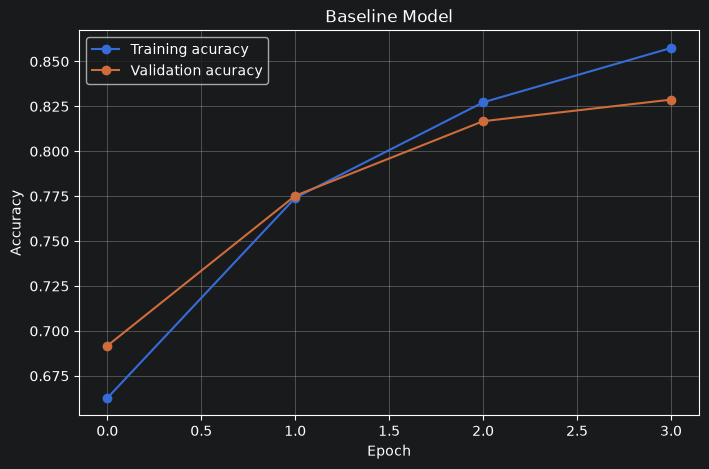

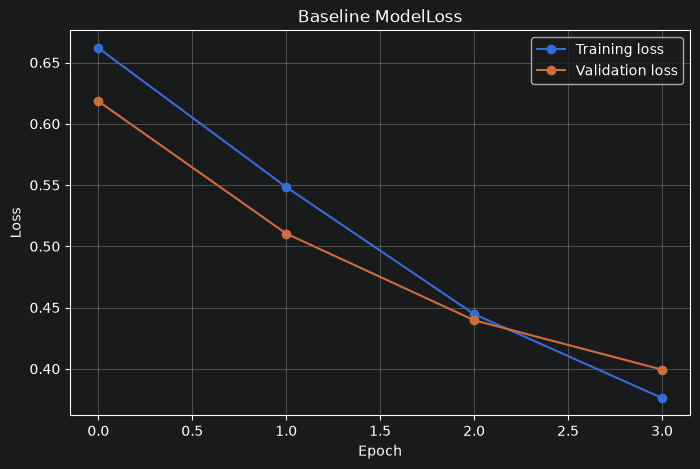

In [11]:
def plot_history(history, title):
    history_dict = history.history

    plt.figure(figsize=(8, 5))
    plt.plot(history_dict["accuracy"], marker="o", label="Training acuracy")
    plt.plot(history_dict["val_accuracy"], marker="o", label="Validation acuracy")
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(history_dict["loss"], marker="o", label="Training loss")
    plt.plot(history_dict["val_loss"], marker="o", label="Validation loss")
    plt.title(title + "Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_history(baseline_history, "Baseline Model")

### Step 12 - Build the Improved LSTM Model

In [14]:
improved_model = tf.keras.Sequential([
    vectorizer,
    tf.keras.layers.Embedding(input_dim=max_token, output_dim=embedding_dim, mask_zero=True, name="baseline_embedding"),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64)),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])

improved_model.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)

In [15]:
improved_history = improved_model.fit(
    train_batches,
    validation_data=val_batches,
    epochs=4,
    shuffle=False,
)

Epoch 1/4


C:\Users\OMID\Documents\PyEnv\PyEnv314\Lib\site-packages\keras\src\layers\layer.py:1092: UserWarning: Layer 'bidirectional_1' (of type Bidirectional) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
C:\Users\OMID\Documents\PyEnv\PyEnv314\Lib\site-packages\keras\src\layers\layer.py:1092: UserWarning: Layer 'forward_lstm_1' (of type LSTM) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
C:\Users\OMID\Documents\PyEnv\PyEnv314\Lib\site-packages\keras\src\layers\layer.py:1092: UserWarning: Layer 'backward_lstm_1' (of type LSTM) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not 

188/188 ━━━━━━━━━━━━━━━━━━━━ 36s 169ms/step - accuracy: 0.7307 - loss: 0.5040 - val_accuracy: 0.8405 - val_loss: 0.5011
Epoch 2/4
188/188 ━━━━━━━━━━━━━━━━━━━━ 26s 140ms/step - accuracy: 0.8865 - loss: 0.2998 - val_accuracy: 0.8558 - val_loss: 0.3362
Epoch 3/4
188/188 ━━━━━━━━━━━━━━━━━━━━ 26s 137ms/step - accuracy: 0.9324 - loss: 0.1918 - val_accuracy: 0.8465 - val_loss: 0.3590
Epoch 4/4
188/188 ━━━━━━━━━━━━━━━━━━━━ 26s 137ms/step - accuracy: 0.9506 - loss: 0.1459 - val_accuracy: 0.8465 - val_loss: 0.4142


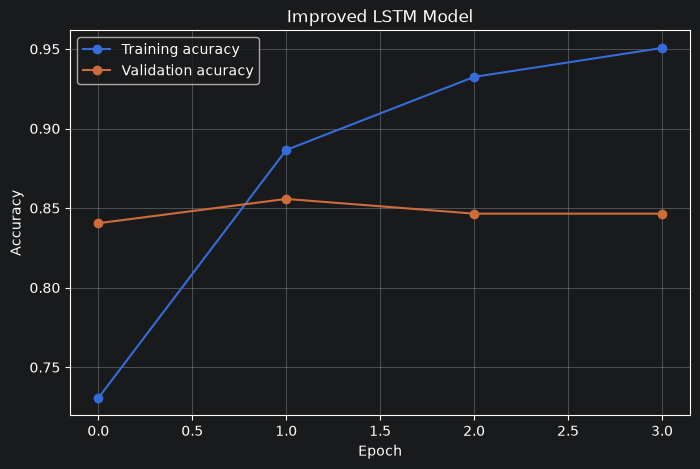

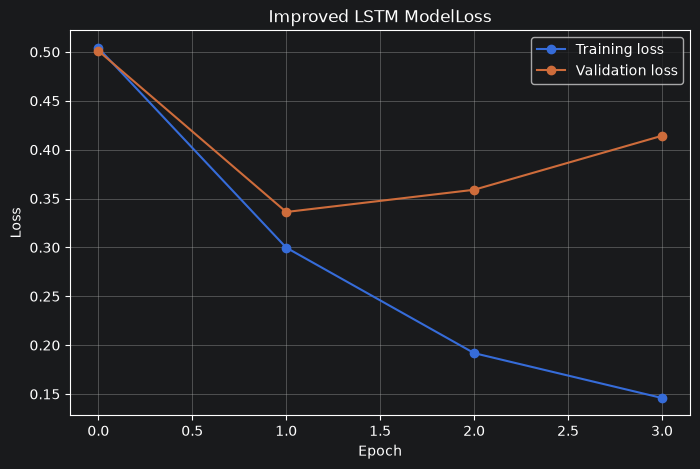

In [16]:
plot_history(improved_history, "Improved LSTM Model")